# Analysis and fine-tuning with geo-embeddings

Pre-computed embeddings turn many Earth-observation tasks into small tabular machine-learning problems. You no longer need imagery, cloud masks or a GPU: a matrix of vectors and a few labels are enough. This notebook walks through the most common workflows, entirely on a laptop CPU:

| Task | Area of interest | Embeddings | Methods |
|---|---|---|---|
| 1. Similarity search | Greenhouses of Almería, Spain | AEF (40 m pooled overviews) | Cosine similarity, FAISS |
| 2. Unsupervised structure | Same | AEF | Incremental PCA, mini-batch k-means, UMAP |
| 3. Change detection | 2023 Evros wildfire, Greece | AEF, 2017–2025 | Year-to-year cosine distance |
| 4. Land-cover classification | Kisumu, Kenya (farms, wetland, town and lake) | AEF, Tessera, OlmoEarth v1.3 | Linear probe, k-NN, spatial cross-validation, learning curves, a fine-tuned MLP head |
| 5. Regression | Kakamega Forest, Kenya | AEF | Ridge and MLP regression of canopy height |
| 6. Comparing models globally | Major TOM 249k sample | OlmoEarth-Base vs SatCLIP image encoder | Nearest-neighbour geography, interactive map |
| Appendix: vector search | Almería, Kisumu | AEF, OlmoEarth v1.3 | Flat vs IVF vs IVF-PQ vs HNSW; cosine vs Euclidean vs dot product; DuckDB `vss` |

Each task uses the AOI that suits it best, rather than one AOI for everything. The companion notebook, [Geo-embedding datasets: a tour and cloud-native access patterns](./geo_embeddings_01_datasets_and_access.md), introduces the datasets and the access patterns reused here.

#### Tip: Running this notebook
Install the dependencies with `uv sync --group notebooks`. All data is read anonymously and cached in `tutorial_cache/`, so only the first run touches the network. That first run transfers roughly 2 GB, more than half of it two Major TOM files in section 6, and takes 10–15 minutes on a typical home connection. Later runs take a few minutes.

## Prefer to have an agent run it?

This notebook is a companion to a set of **agent skills** for geo-embeddings: [geo-embeddings skills on GitHub](https://github.com/geo-embeddings/Geo-R-Ges). The notebook explains the *why* and shows every line of code. The skills package the same workflows so that an AI coding agent, such as Claude Code, can run them for you on your own area of interest.

A skill is a folder with a `SKILL.md` file, holding instructions plus a short description of when to use them, and optionally some helper scripts. The agent reads only the descriptions up front and loads a skill's full instructions when your request calls for it.

To use them:

1. **Get the skills:** `git clone https://github.com/geo-embeddings/Geo-R-Ges`
2. **Put them where your agent looks.** For Claude Code, copy a skill's folder into `.claude/skills/` in your project, or into `~/.claude/skills/` to use it in every project. In the Claude apps, upload the zipped skill folder under *Settings → Capabilities*. Other agents that support the Agent Skills format use their own locations, so check their documentation.
3. **Ask in plain language.** For example:
   - *"Map land cover around Kisumu from embeddings and WorldCover labels, and report spatially cross-validated accuracy."*
   - *"Find the areas in this AOI whose embeddings changed most between 2022 and 2024."*

   The agent picks up the matching skill automatically. In Claude Code you can also call a skill directly with `/<skill-name>`.
4. **Review what it did.** The agent writes and runs code much like the cells below. Use this notebook to sanity-check its choices, especially de-quantization, normalization and spatial validation.

## Setup

In [1]:
# torch, scikit-learn and faiss each bundle their own OpenMP runtime, which can deadlock or crash
# on macOS. Importing torch first, then the rest, and keeping faiss single-threaded (below) avoids
# the conflict; keep this import order if you rearrange the cell.
import torch

import time
import warnings
from pathlib import Path

import duckdb
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA, IncrementalPCA
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             mean_absolute_error, r2_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from zarr.errors import ZarrUserWarning

warnings.simplefilter('ignore', ZarrUserWarning)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['savefig.dpi'] = 80

CACHE = Path('tutorial_cache')
CACHE.mkdir(exist_ok=True)
SOURCE_COOP_S3 = 's3://us-west-2.opendata.source.coop'
# GDAL options for anonymous reads straight from the bucket (rasterio uses GDAL under the hood)
GDAL_S3 = dict(AWS_NO_SIGN_REQUEST='YES', AWS_REGION='us-west-2', GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR')

rng = np.random.default_rng(0)
torch.manual_seed(0)
torch.set_num_threads(4)
faiss.omp_set_num_threads(1)  # exact search over ~1M vectors is still milliseconds

### Readers with a local cache

Each reader fetches an AOI once, keeps it in its stored dtype (int8 for every product here), and saves it to `tutorial_cache/` as a small `.npz` file. Later runs, or a kernel restart, load from disk.

- `read_aef_mosaic` reads full-resolution AEF from the GeoZarr mosaic (EPSG:4326).
- `read_aef_cog` reads AEF from a UTM COG, optionally decimated, which returns the **pooled overview** embeddings described in the first notebook.
- `read_utm_zarr` reads one UTM zone group from the Tessera or OlmoEarth Zarr stores.

In [2]:
def cached(name, fetch, crs):
    """Return the (band, y, x) DataArray from `fetch()`, cached as tutorial_cache/<name>.npz."""
    path = CACHE / f'{name}.npz'
    if not path.exists():
        t0 = time.perf_counter()
        da = fetch()
        extra = {k: v.values for k, v in da.coords.items() if k not in ('band', 'y', 'x')}
        np.savez(path, values=da.values, y=da.y.values, x=da.x.values, **extra)
        print(f'{name}: fetched {da.nbytes / 1e6:.0f} MB in {time.perf_counter() - t0:.0f} s')
    f = np.load(path)
    dims = ('band', 'y', 'x') if f['values'].ndim == 3 else ('y', 'x')
    return xr.DataArray(f['values'], dims=dims, coords={'y': f['y'], 'x': f['x']}).rio.write_crs(crs)


def read_aef_mosaic(bbox, year):
    aef = xr.open_zarr(f'{SOURCE_COOP_S3}/tge-labs/aef-mosaic/', storage_options={'anon': True},
                       consolidated=False, chunks=None)
    return aef['embeddings'].sel(time=year, x=slice(bbox[0], bbox[2]), y=slice(bbox[3], bbox[1])).load()


AEF_INDEX = f'{SOURCE_COOP_S3}/tge-labs/aef/v1/annual/aef_index_stac_geoparquet.parquet'


def read_aef_cog(bbox, year, factor):
    """Read the AEF COG that contains `bbox`, decimated by `factor` (uses the pooled overviews)."""
    con = duckdb.connect()
    con.sql("LOAD spatial; LOAD httpfs; SET s3_region='us-west-2';")
    rows = con.sql(f'''
        SELECT assets.data.href FROM '{AEF_INDEX}' WHERE year(datetime AT TIME ZONE 'UTC') = {year}
          AND bbox.xmin <= {bbox[0]} AND bbox.xmax >= {bbox[2]} AND bbox.ymin <= {bbox[1]} AND bbox.ymax >= {bbox[3]}
    ''').fetchall()
    if not rows:
        raise ValueError(f'no single AEF COG contains {bbox} in {year}')
    with rasterio.Env(**GDAL_S3), rasterio.open(rows[0][0].replace('s3://', '/vsis3/')) as src:
        T = src.transform  # bottom-up file: T.e > 0, row 0 is the southern edge
        left, bottom, right, top = transform_bounds('EPSG:4326', src.crs, *bbox)
        c0, c1 = int((left - T.c) // T.a), int((right - T.c) // T.a) + 1
        r0, r1 = int((bottom - T.f) // T.e), int((top - T.f) // T.e) + 1
        h, w = (r1 - r0) // factor, (c1 - c0) // factor
        data = src.read(window=rasterio.windows.Window(c0, r0, w * factor, h * factor), out_shape=(src.count, h, w))
    res = T.a * factor
    x = T.c + c0 * T.a + (np.arange(w) + 0.5) * res
    y = T.f + (r0 + h * factor) * T.e - (np.arange(h) + 0.5) * res
    return xr.DataArray(np.flip(data, axis=1), dims=('band', 'y', 'x'), coords={'y': y, 'x': x})


def read_utm_zarr(store, bbox, year, epsg, var='embeddings'):
    """Read one variable for `bbox` from a per-UTM-zone Zarr store (Tessera, OlmoEarth)."""
    ds = xr.open_zarr(f'{store}/utm{epsg % 100:02d}', storage_options={'anon': True},
                      consolidated=False, chunks=None)
    xmin, ymin, xmax, ymax = transform_bounds('EPSG:4326', f'EPSG:{epsg}', *bbox)
    return ds[var].sel(time=year, x=slice(xmin, xmax), y=slice(ymax, ymin)).load()


TESSERA = f'{SOURCE_COOP_S3}/tessera/tessera/zarr/v1.1-dclimate'
OLMOEARTH = f'{SOURCE_COOP_S3}/olmoearth/olmoearth-v1-3-embeddings/embeddings.zarr'

De-quantization and a few array helpers. All three pixel products are stored as int8, with `-128` as no-data (AEF, OlmoEarth) or a NaN scale (Tessera). Why the de-quantization step matters is explained with real data in section 1.

In [3]:
def dequantize_signed_square(raw):
    """AEF / OlmoEarth int8 -> float32; -128 becomes NaN."""
    x = raw.values.astype(np.float32)
    out = np.sign(x) * (np.abs(x) / 127.5) ** 2
    out[raw.values == -128] = np.nan
    return raw.copy(data=out)


def to_matrix(emb):
    """(band, y, x) -> (y * x, band) float32 matrix."""
    return emb.values.reshape(emb.shape[0], -1).T


def l2_normalize(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)


def pca_rgb(X, fit_sample=200_000):
    """(n, d) -> (n, 3) colours in [0, 1] from the first three principal components (NaN rows -> white)."""
    valid = ~np.isnan(X).any(axis=1)
    idx = np.flatnonzero(valid)
    pca = PCA(n_components=3).fit(X[rng.choice(idx, min(fit_sample, len(idx)), replace=False)])
    pcs = pca.transform(X[valid])
    lo, hi = np.percentile(pcs, [2, 98], axis=0)
    out = np.ones((len(X), 3))
    out[valid] = np.clip((pcs - lo) / (hi - lo), 0, 1)
    return out


def extent_of(da):
    """matplotlib imshow extent for a DataArray with y/x pixel-centre coordinates."""
    dx, dy = abs(float(da.x[1] - da.x[0])), abs(float(da.y[1] - da.y[0]))
    return (float(da.x.min()) - dx / 2, float(da.x.max()) + dx / 2,
            float(da.y.min()) - dy / 2, float(da.y.max()) + dy / 2)

## 1. Similarity search: finding greenhouses in Almería

The Campo de Dalías and Níjar areas of Almería hold one of the largest concentrations of greenhouses in the world, the "sea of plastic". Greenhouses are visually distinctive, which makes them a clean test of **search by example**: pick one pixel, then rank every other pixel by how similar its embedding is.

The AOI spans about 76 km × 35 km. At full resolution that would be ~27 million pixels (1.7 GB as int8). For a regional search, the **40 m pooled overview** of the AEF COG is plenty, at 1/16 of the data.

In [4]:
ALMERIA = (-2.95, 36.68, -2.10, 37.00)
alm_raw = cached('aef_almeria_2024_40m', lambda: read_aef_cog(ALMERIA, 2024, factor=4), crs='EPSG:32630')
alm = dequantize_signed_square(alm_raw)
X_alm = to_matrix(alm)
alm_valid = ~np.isnan(X_alm).any(axis=1)
alm_extent = extent_of(alm)
alm_rgb = pca_rgb(X_alm).reshape(*alm.shape[1:], 3)
print(f'{alm.shape[1]} x {alm.shape[2]} pixels at 40 m; {alm_valid.mean():.1%} valid')

897 x 1899 pixels at 40 m; 100.0% valid


### Note on de-quantization

Before any analysis, the stored int8 codes must be converted back to floating-point embedding values. It is tempting to skip that step, since the codes are monotonic in the values, but it is not optional.

**How AEF is quantized.** An AEF vector has unit length across 64 dimensions, so a typical component is small, around ±1/√64 ≈ ±0.125, and values near ±1 are very rare. A plain *linear* int8 mapping of [-1, 1] onto codes -127…127 would spend most of its 255 codes on values that almost never occur and squeeze the common small values into a few dozen codes near zero.

AEF instead stores roughly `q = sign(v) · 127.5 · √|v|`, a square-root companding curve like those used in audio codecs. The square root stretches the crowded region near zero across many more codes. De-quantizing inverts it:

`v = sign(q) · (|q| / 127.5)²`

The step between neighbouring codes is then tiny near zero and grows towards ±1. Precision goes where the data is: the resolution of the codes tracks the density of the values, and the code range is used far more evenly. OlmoEarth v1.3 uses the same signed-square scheme. Its vectors are not unit length, but its components are also concentrated near zero.

The cell below compares how many codes are actually used under each scheme, for the same AEF values:

central 99% of values span 148 of 255 codes with signed-square quantization, 85 with linear quantization


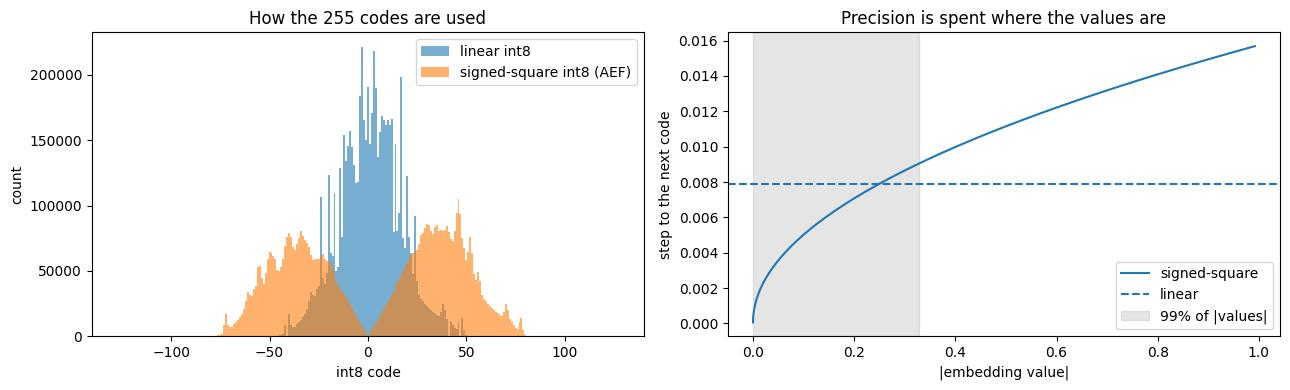

In [5]:
codes = alm_raw.values[:, ::4, ::4].ravel()  # a sample of the stored codes
codes = codes[codes != -128]
values = np.sign(codes) * (np.abs(codes.astype(np.float32)) / 127.5) ** 2  # de-quantized
linear_codes = np.round(values * 127)  # what a plain linear int8 mapping would store instead


def codes_spanned(c, pct=99):
    """Number of distinct codes spanned by the central `pct`% of values."""
    lo, hi = np.percentile(c, [(100 - pct) / 2, (100 + pct) / 2])
    return int(hi - lo) + 1


print(f'central 99% of values span {codes_spanned(codes)} of 255 codes with signed-square quantization, '
      f'{codes_spanned(linear_codes)} with linear quantization')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(-127.5, 128.5)
axes[0].hist(linear_codes, bins=bins, alpha=0.6, label='linear int8')
axes[0].hist(codes, bins=bins, alpha=0.6, label='signed-square int8 (AEF)')
axes[0].set_xlabel('int8 code')
axes[0].set_ylabel('count')
axes[0].set_title('How the 255 codes are used')
axes[0].legend()
q = np.arange(0, 128)
axes[1].plot(q / 127.5 * q / 127.5, (2 * q + 1) / 127.5 ** 2, label='signed-square')
axes[1].axhline(1 / 127, color='C0', linestyle='--', label='linear')
axes[1].axvspan(0, np.percentile(np.abs(values), 99), color='grey', alpha=0.2, label='99% of |values|')
axes[1].set_xlabel('|embedding value|')
axes[1].set_ylabel('step to the next code')
axes[1].set_title('Precision is spent where the values are')
axes[1].legend()
plt.tight_layout()
plt.show()

Skipping de-quantization, or doing it carelessly, breaks things in three ways:

1. **Distances are distorted.** The mapping is non-linear, so dot products, cosine similarities and Euclidean distances computed on raw codes don't match the real ones. Large components are understated relative to small ones.
2. **No-data becomes data.** `-128` is a sentinel, not a value. Left in, it turns into a large negative component in every band and silently corrupts means, PCA and nearest neighbours. Convert it to NaN, as `dequantize_signed_square` does.
3. **Integer arithmetic overflows.** NumPy keeps int8 arithmetic in int8, so products of codes wrap around without warning.

In [6]:
a, b = alm_raw.values[:, 500, 500], alm_raw.values[:, 500, 501]  # two neighbouring pixels
print('int8 products wrap around:', (a * b)[:6], 'vs', (a.astype(np.int32) * b)[:6])

pairs = rng.choice(np.flatnonzero(alm_valid), (5000, 2))
raw = to_matrix(alm_raw).astype(np.float32)
cos = lambda M: (l2_normalize(M[pairs[:, 0]]) * l2_normalize(M[pairs[:, 1]])).sum(axis=1)
err = np.abs(cos(raw) - cos(X_alm))
print(f'cosine similarity on raw codes vs de-quantized values: mean error {err.mean():.3f}, max {err.max():.3f}')

int8 products wrap around: [ 60  75 -64  56 122  88] vs [3132 2891  704 -200 -390 -680]
cosine similarity on raw codes vs de-quantized values: mean error 0.037, max 0.173


The other datasets handle this differently:

- **Tessera** uses *linear* int8 codes multiplied by a **per-pixel float32 scale** (`v = q · scale`). Each pixel gets its own scale, so every pixel uses the full code range regardless of its magnitude. You must multiply by the scale, and a NaN scale marks no-data.
- **Clay and Earth Index** store plain float32 (4× larger), so there is nothing to undo, but they are not unit length either.

The quantization scheme travels with the data in the `geoemb:quantization` metadata of the [Embeddings Zarr Convention](/standards), so always check it before using a new product.

### Search by example

The query is a single pixel in the middle of the Campo de Dalías. AEF vectors are unit length, so cosine similarity is a plain matrix-vector product. On a laptop it takes well under a second for 1.7 million pixels.

cosine similarity for 1,703,403 pixels in 283 ms


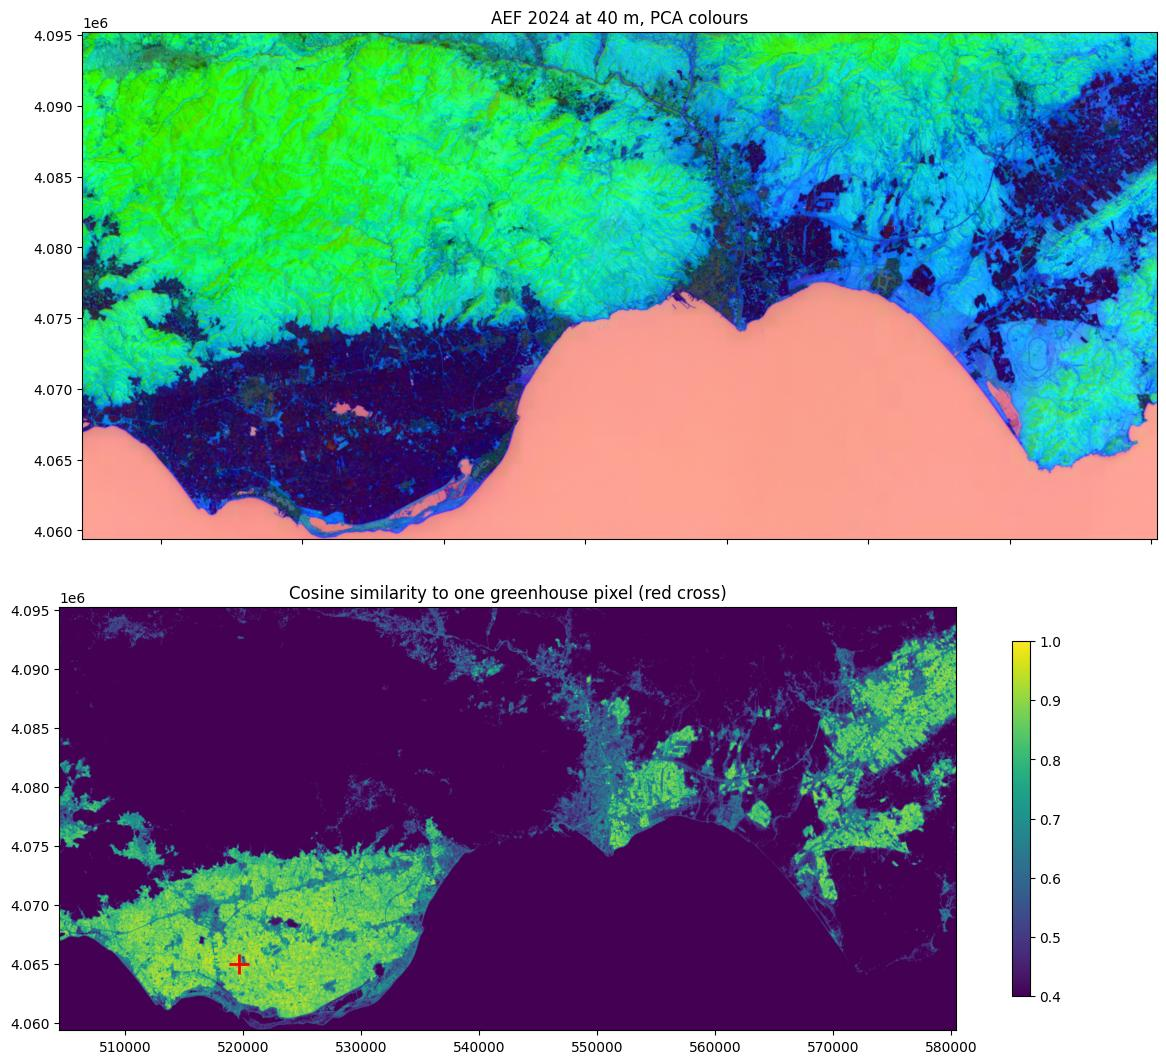

In [7]:
to_utm30 = Transformer.from_crs('EPSG:4326', 'EPSG:32630', always_xy=True)
query_xy = to_utm30.transform(-2.78, 36.73)
query = alm.sel(x=query_xy[0], y=query_xy[1], method='nearest').values

t0 = time.perf_counter()
similarity = np.where(alm_valid, np.nan_to_num(X_alm) @ query, np.nan).reshape(alm.shape[1:])
print(f'cosine similarity for {alm_valid.sum():,} pixels in {1000 * (time.perf_counter() - t0):.0f} ms')

fig, axes = plt.subplots(2, 1, figsize=(12, 11), sharex=True)
axes[0].imshow(alm_rgb, extent=alm_extent)
axes[0].set_title('AEF 2024 at 40 m, PCA colours')
im = axes[1].imshow(similarity, extent=alm_extent, vmin=0.4, vmax=1, cmap='viridis')
axes[1].plot(*query_xy, 'r+', markersize=14, markeredgewidth=2)
axes[1].set_title('Cosine similarity to one greenhouse pixel (red cross)')
plt.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout()
plt.show()

A single example lights up not only the Campo de Dalías but also the greenhouse clusters around Almería city and Níjar, 30–50 km away, which the query never "saw". Thresholding the similarity gives a rough greenhouse map and area estimate. The threshold is a judgment call; the histogram helps.

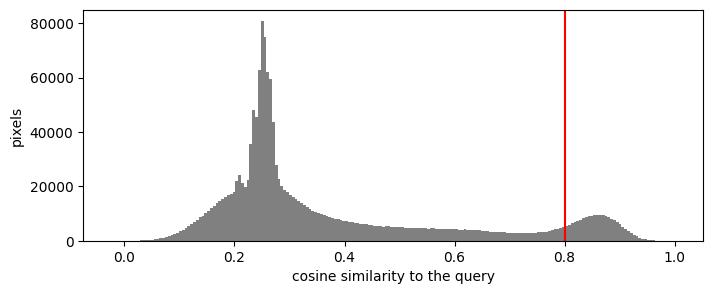

pixels above 0.8: 292 km²


In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(similarity[np.isfinite(similarity)], bins=200, color='grey')
THRESHOLD = 0.8
ax.axvline(THRESHOLD, color='red')
ax.set_xlabel('cosine similarity to the query')
ax.set_ylabel('pixels')
plt.show()

pixel_km2 = (40 / 1000) ** 2
print(f'pixels above {THRESHOLD}: {(similarity > THRESHOLD).sum() * pixel_km2:.0f} km²')

### Top-k search with FAISS

When you want the *k most similar* items rather than a full similarity map, a vector index is the right tool. [FAISS](https://github.com/facebookresearch/faiss) runs on CPU. `IndexFlatIP` does exact inner-product search, which equals cosine similarity for unit vectors. For millions of vectors that is still fast; approximate indexes (`IndexHNSWFlat`, `IndexIVFFlat`) trade a little recall for speed at the 100M+ scale.

A KD-tree (SciPy, scikit-learn) is a poor fit here: in 64+ dimensions it degrades to roughly brute force.

top 5,000 of 1,703,403 vectors in 25 ms; score range 0.946-0.977


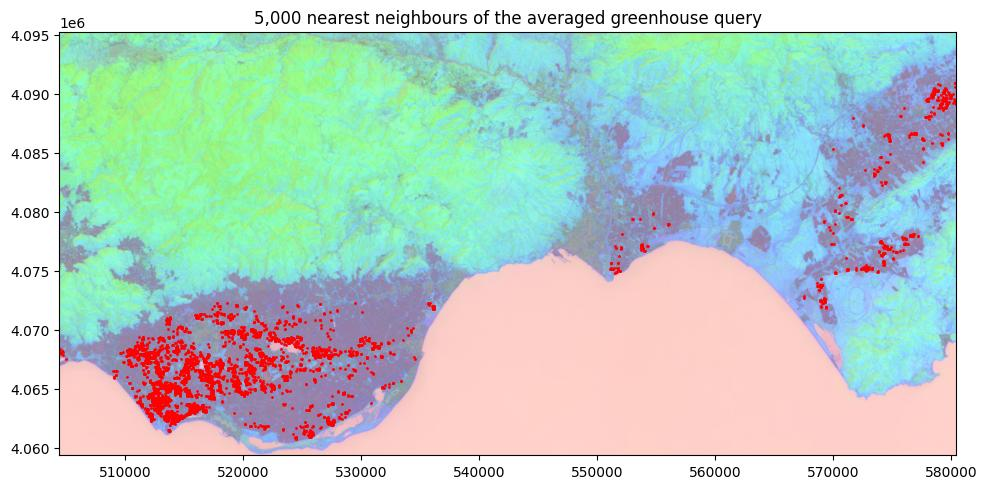

In [9]:
valid_idx = np.flatnonzero(alm_valid)
index = faiss.IndexFlatIP(X_alm.shape[1])
index.add(np.ascontiguousarray(X_alm[valid_idx]))

# three exemplars from different parts of the Campo de Dalías; averaging them makes the query more robust
exemplars = [to_utm30.transform(lon, lat) for lon, lat in [(-2.78, 36.73), (-2.83, 36.75), (-2.72, 36.76)]]
q = np.mean([alm.sel(x=x, y=y, method='nearest').values for x, y in exemplars], axis=0)
q = (q / np.linalg.norm(q)).astype(np.float32)[None]

t0 = time.perf_counter()
scores, hits = index.search(q, 5000)
print(f'top 5,000 of {index.ntotal:,} vectors in {1000 * (time.perf_counter() - t0):.0f} ms; '
      f'score range {scores.min():.3f}-{scores.max():.3f}')

rows, cols = np.unravel_index(valid_idx[hits[0]], alm.shape[1:])
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.imshow(alm_rgb, extent=alm_extent, alpha=0.5)
ax.scatter(alm.x.values[cols], alm.y.values[rows], s=1, c='red')
ax.set_title('5,000 nearest neighbours of the averaged greenhouse query')
plt.show()

## 2. Unsupervised structure: PCA, clustering and UMAP without loading everything

Clustering is the quickest way to see what an embedding space "knows" about a region. The scikit-learn estimators below support `partial_fit`, so they can learn from **blocks of rows**, and the full float32 matrix never has to exist in memory. That is how you would process an AOI too large for RAM, streaming blocks from Zarr or COG windows. Here we stream row blocks from the cached int8 array and de-quantize one block at a time.

In [10]:
def blocks(raw, rows_per_block=128):
    """Yield de-quantized (n, band) matrices for successive row blocks of an int8 (band, y, x) array."""
    for r in range(0, raw.shape[1], rows_per_block):
        X = to_matrix(dequantize_signed_square(raw[:, r:r + rows_per_block]))
        yield X[~np.isnan(X).any(axis=1)]


ipca = IncrementalPCA(n_components=8)
kmeans = MiniBatchKMeans(n_clusters=8, random_state=0, batch_size=4096, n_init=3)
for X_block in blocks(alm_raw):
    ipca.partial_fit(X_block)
for X_block in blocks(alm_raw):
    kmeans.partial_fit(X_block)

print('explained variance of first 8 components:', ipca.explained_variance_ratio_.round(3))
clusters = np.full(len(X_alm), -1)
clusters[alm_valid] = kmeans.predict(X_alm[alm_valid])

explained variance of first 8 components: [0.379 0.207 0.077 0.063 0.052 0.034 0.025 0.017]


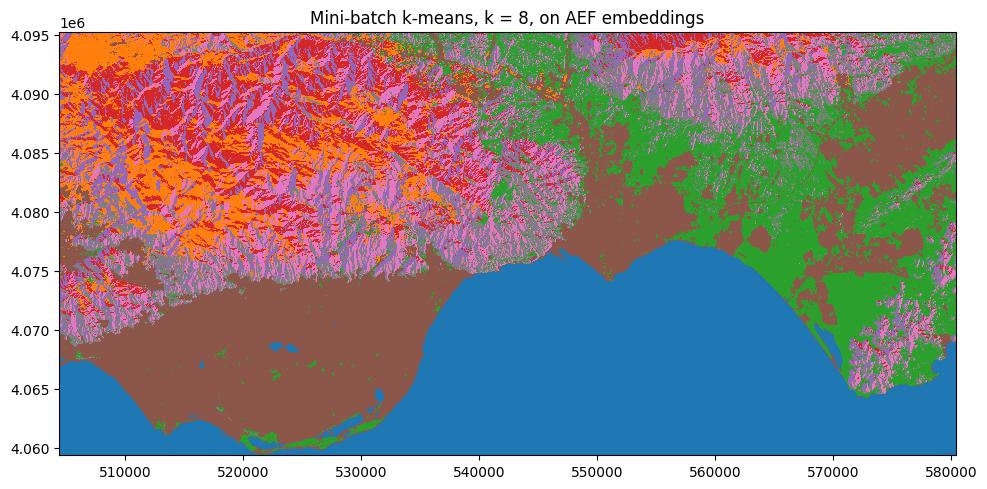

In [11]:
cluster_cmap = ListedColormap(plt.cm.tab10.colors[:8])
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.imshow(np.ma.masked_less(clusters.reshape(alm.shape[1:]), 0), extent=alm_extent,
          cmap=cluster_cmap, interpolation='nearest')
ax.set_title('Mini-batch k-means, k = 8, on AEF embeddings')
plt.show()

Without labels, k-means splits off the sea and the greenhouse-covered coastal plains (merged with other built-up lowland at this k), and divides the Sierra de Gádor and the surrounding hills into clusters that follow vegetation and **slope aspect**: sun-facing and shaded slopes look different from orbit, and the embeddings pick that up. The number of clusters is arbitrary, so try a few values of `k`. [UMAP](https://umap-learn.readthedocs.io) shows the same structure as a 2-D map of the embedding space. It is quadratic-ish in memory, so run it on a sample:

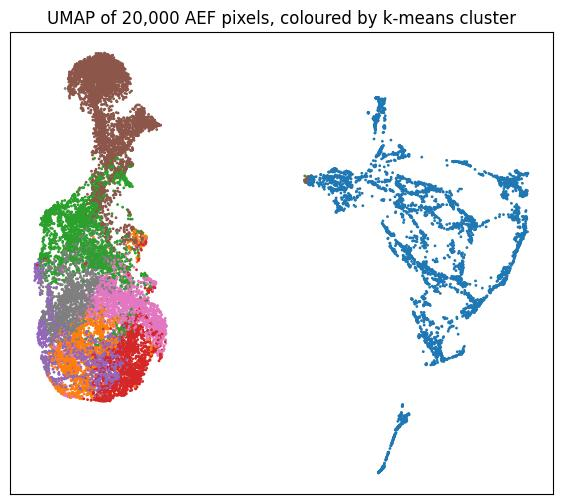

In [12]:
import umap

warnings.filterwarnings('ignore', message='n_jobs value')  # fixing random_state disables UMAP's parallelism
sample = rng.choice(np.flatnonzero(alm_valid), 20_000, replace=False)
xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(X_alm[sample])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(*xy.T, s=1, c=clusters[sample], cmap=cluster_cmap, vmin=0, vmax=7)
ax.set_title('UMAP of 20,000 AEF pixels, coloured by k-means cluster')
ax.set_xticks([])
ax.set_yticks([])
plt.show()

## 3. Change detection: the 2023 Evros wildfire

In August 2023 a wildfire in the Evros region of north-eastern Greece, including the Dadia forest, became the largest recorded in the EU. Annual embeddings make change detection almost trivial: **if a place changed, its embedding moves**, so the cosine distance between two years is a change score.

Two practical points:

- **Pick years that bracket the event.** An annual AEF embedding summarises the whole year, so 2023 mixes pre- and post-fire conditions. Comparing 2022 with 2024 gives a clean before/after.
- **Use the pooled overviews.** Burn scars are kilometres across, so 80 m embeddings are plenty, and nine years of them cost less than one year at full resolution.

The AOI covers the western half of the burned area, which fits inside a single AEF COG.

In [13]:
EVROS = (25.65, 40.80, 26.00, 41.10)
YEARS = range(2017, 2026)
evros = {year: dequantize_signed_square(cached(f'aef_evros_{year}_80m', lambda: read_aef_cog(EVROS, year, factor=8),
                                               crs='EPSG:32635'))
         for year in YEARS}
evros_extent = extent_of(evros[2022])
print(evros[2022].shape)

(64, 421, 374)


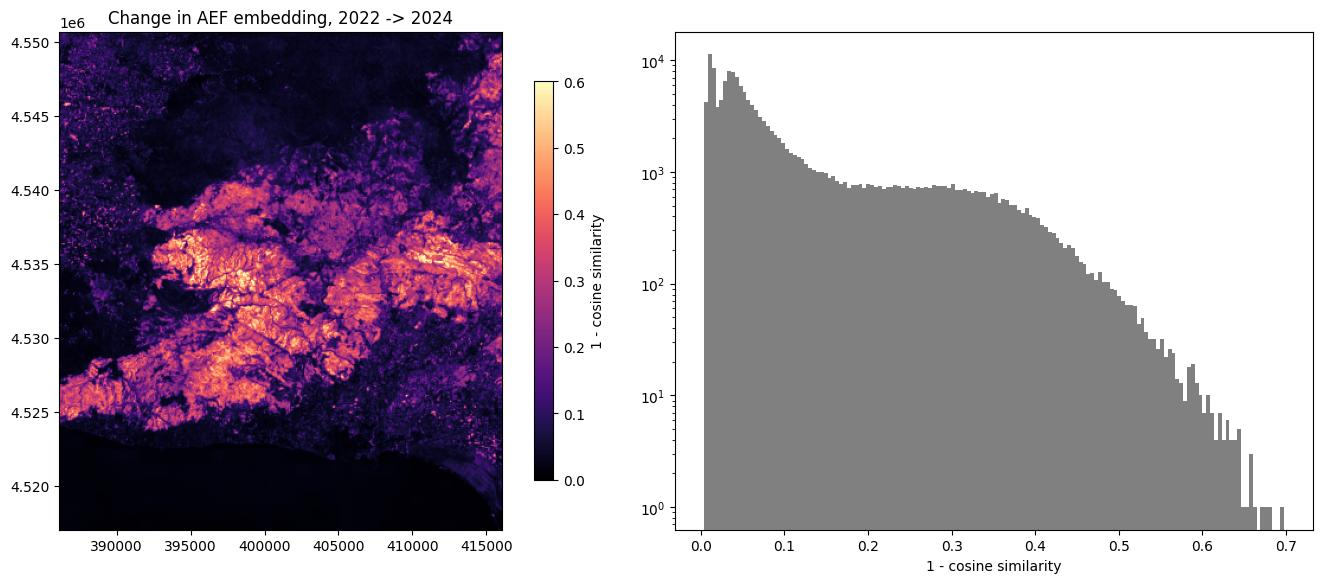

In [14]:
def cosine_similarity_map(a, b):
    """Per-pixel cosine similarity between two (band, y, x) embedding arrays."""
    return (a * b).sum('band') / (np.sqrt((a ** 2).sum('band')) * np.sqrt((b ** 2).sum('band')))


change = 1 - cosine_similarity_map(evros[2022], evros[2024])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im = axes[0].imshow(change, extent=evros_extent, vmin=0, vmax=0.6, cmap='magma')
plt.colorbar(im, ax=axes[0], shrink=0.8, label='1 - cosine similarity')
axes[0].set_title('Change in AEF embedding, 2022 -> 2024')
axes[1].hist(change.values.ravel(), bins=150, color='grey')
axes[1].set_yscale('log')
axes[1].set_xlabel('1 - cosine similarity')
plt.tight_layout()
plt.show()

The burn scar stands out sharply against a stable background. Most unchanged pixels score below ~0.1, which is the year-to-year noise floor. Thresholding gives a burned-area estimate. With a single threshold this is rough; a few labelled burned and unburned points, plus the classifier from section 4, would do better.

In [15]:
CHANGE_THRESHOLD = 0.25
burned = change.values > CHANGE_THRESHOLD
print(f'changed area in this AOI: {burned.sum() * 0.08 ** 2:.0f} km² of {burned.size * 0.08 ** 2:.0f} km²')

changed area in this AOI: 165 km² of 1008 km²


Because every year is available, we can also follow the burned pixels **through time**, measuring each year's similarity to the pre-fire 2022 baseline. Unburned pixels show the normal year-to-year variability.

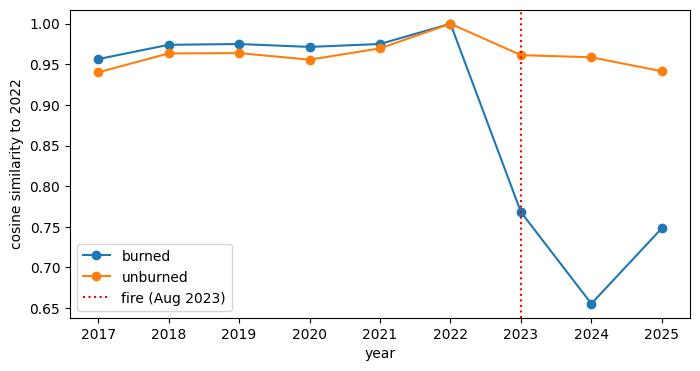

year,2017,2018,2019,2020,2021,2022,2023,2024,2025
burned,0.956,0.974,0.975,0.971,0.975,1.0,0.768,0.655,0.748
unburned,0.940,0.963,0.964,0.956,0.970,1.0,0.961,0.959,0.942


In [16]:
stable = change.values < 0.1
records = []
for year in YEARS:
    sim = cosine_similarity_map(evros[2022], evros[year]).values
    records.append({'year': year, 'burned': np.nanmean(sim[burned]), 'unburned': np.nanmean(sim[stable])})
trajectory = pd.DataFrame(records).set_index('year')

ax = trajectory.plot(marker='o', figsize=(8, 4))
ax.axvline(2023, color='red', linestyle=':', label='fire (Aug 2023)')
ax.set_ylabel('cosine similarity to 2022')
ax.legend()
plt.show()
trajectory.round(3).T

The burned pixels drop in 2023, when the year mixes pre- and post-fire conditions, bottom out in 2024, and only begin to move back by 2025. The earlier years show how much a stable landscape normally drifts from one year to the next.

## 4. Land-cover classification in western Kenya

Now a supervised task: map land cover around **Kisumu** on the shore of Lake Victoria, a mosaic of smallholder farms, wetlands, grassland, trees, town and lake. We use three pixel-embedding products for the same year (2021) and train simple models on labels from [ESA WorldCover 2021](https://esa-worldcover.org), which is itself a public COG.

#### Note: WorldCover is a model too
WorldCover's own overall accuracy is around 75–80%, and smallholder cropland is one of its harder classes. Treat agreement with WorldCover as a *relative* score for comparing approaches, not ground truth. For real work, use field-collected or carefully photo-interpreted labels.

### Load three embeddings and the labels on one grid

Tessera and OlmoEarth share the same 10 m UTM grid (zone 36), so we use it as the common grid. AEF and WorldCover are resampled onto it with **nearest-neighbour**, the only safe choice for both embeddings and categorical labels.

In [17]:
KISUMU = (34.72, -0.14, 34.82, -0.04)
EPSG = 32636  # UTM zone 36; both stores keep southern locations in the northern CRS (negative y)

olmo_raw = cached('olmoearth_kisumu_2021', lambda: read_utm_zarr(OLMOEARTH, KISUMU, 2021, EPSG), crs=f'EPSG:{EPSG}')
tess_q = cached('tessera_kisumu_2021', lambda: read_utm_zarr(TESSERA, KISUMU, 2021, EPSG), crs=f'EPSG:{EPSG}')
tess_s = cached('tessera_scales_kisumu_2021', lambda: read_utm_zarr(TESSERA, KISUMU, 2021, EPSG, 'scales'),
                crs=f'EPSG:{EPSG}')
aef_raw = cached('aef_kisumu_2021', lambda: read_aef_mosaic(KISUMU, 2021), crs='EPSG:4326')

grid = olmo_raw
embeddings = {
    'AEF': dequantize_signed_square(
        aef_raw.rio.write_nodata(-128).rio.reproject_match(grid, resampling=Resampling.nearest)),
    'Tessera': tess_q.astype(np.float32) * tess_s,
    'OlmoEarth v1.3': dequantize_signed_square(olmo_raw),
}
for name, emb in embeddings.items():
    print(f'{name:15s} {emb.shape}')

AEF             (64, 1106, 1113)
Tessera         (128, 1106, 1113)
OlmoEarth v1.3  (128, 1106, 1113)


In [18]:
WORLDCOVER = {10: 'tree cover', 20: 'shrubland', 30: 'grassland', 40: 'cropland', 50: 'built-up',
              60: 'bare', 80: 'water', 90: 'wetland'}
wc_url = 'https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_S03E033_Map.tif'
labels_raw = cached('worldcover_kisumu_2021', lambda: rioxarray.open_rasterio(wc_url).squeeze(drop=True)
                    .rio.clip_box(*KISUMU).rio.reproject_match(grid, resampling=Resampling.nearest),
                    crs=f'EPSG:{EPSG}')
labels = labels_raw.values
counts = pd.Series(labels.ravel()).map(WORLDCOVER).value_counts(normalize=True)
counts.round(3)

tree cover    0.260
grassland     0.202
built-up      0.192
shrubland     0.181
water         0.108
cropland      0.042
wetland       0.012
bare          0.004
Name: proportion, dtype: float64

We keep the classes that cover at least 1% of the AOI. Then we draw a **class-balanced sample**, at most 1,500 labelled pixels per class, and record which 1 km × 1 km block each pixel falls in, for spatial cross-validation.

In [19]:
classes = [c for c, name in WORLDCOVER.items() if counts.get(name, 0) >= 0.01]
class_names = [WORLDCOVER[c] for c in classes]
H, W = labels.shape
mats = {name: to_matrix(emb) for name, emb in embeddings.items()}
valid = np.isin(labels.ravel(), classes) & np.all([~np.isnan(M).any(axis=1) for M in mats.values()], axis=0)

sample = np.concatenate([
    rng.choice(np.flatnonzero(valid & (labels.ravel() == c)),
               min(1500, (valid & (labels.ravel() == c)).sum()), replace=False)
    for c in classes])
y = np.searchsorted(classes, labels.ravel()[sample])
rows, cols = np.unravel_index(sample, (H, W))
groups = (rows // 100) * 1000 + cols // 100  # 100 px = 1 km blocks
print(f'{len(sample):,} labelled pixels in {len(np.unique(groups))} spatial blocks; classes: {class_names}')

10,500 labelled pixels in 144 spatial blocks; classes: ['tree cover', 'shrubland', 'grassland', 'cropland', 'built-up', 'water', 'wetland']


### Linear probe and k-NN, with honest validation

A **linear probe** (logistic regression on frozen embeddings) is the standard way to measure how much task-relevant information an embedding holds. k-nearest neighbours is the other classic baseline.

How you split train and test matters as much as the model. Neighbouring pixels are nearly identical, so a **random** split puts near-duplicates of test pixels in the training set, and scores look better than they will be on new areas. A **spatial** split (`GroupKFold` over 1 km blocks) holds out whole blocks.

OlmoEarth appears twice: with all 128 dimensions, and with only the first 64 (its Matryoshka prefix).

In [20]:
features = {**{name: M[sample] for name, M in mats.items()},
            'OlmoEarth v1.3 (64-d)': mats['OlmoEarth v1.3'][sample, :64]}
models = {
    'linear probe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
    'k-NN (k=10)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10)),
}
results = []
for (model_name, model) in models.items():
    for feat_name, X in features.items():
        for split_name, cv, kw in [('random', KFold(5, shuffle=True, random_state=0), {}),
                                   ('spatial', GroupKFold(5), {'groups': groups})]:
            scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro'], n_jobs=-1, **kw)
            results.append({'model': model_name, 'embedding': feat_name, 'split': split_name,
                            'accuracy': scores['test_accuracy'].mean(), 'macro_F1': scores['test_f1_macro'].mean()})

pd.DataFrame(results).pivot_table(index=['model', 'embedding'], columns='split', values='macro_F1').round(3)

split                               random  spatial
model        embedding                             
k-NN (k=10)  AEF                     0.773    0.746
             OlmoEarth v1.3          0.798    0.779
             OlmoEarth v1.3 (64-d)   0.798    0.773
             Tessera                 0.769    0.753
linear probe AEF                     0.795    0.779
             OlmoEarth v1.3          0.829    0.807
             OlmoEarth v1.3 (64-d)   0.828    0.813
             Tessera                 0.819    0.802

Three things to read from this table:

1. **Random splits score higher, every time.** Here the gap is modest, 1.5–3 points of macro F1, because the sample is spread thinly over 144 blocks. It grows when training points are clustered, as they are in most real field campaigns, and when the map is applied far from the training area. Always report spatial validation for maps.
2. **The embeddings differ, but only by a few points.** On this AOI, with these noisy labels, OlmoEarth v1.3 scores highest, Tessera close behind, and AEF a few points lower. A single AOI is not a benchmark, so test on your own region and labels before choosing.
3. **OlmoEarth's 64-d prefix matches the full 128 dimensions** here, for half the download and half the memory.

### How many labels do you need?

A learning curve answers the most practical question in any mapping project. We hold out 30% of the spatial blocks as a fixed test set and train on increasing numbers of labels per class drawn from the remaining blocks:

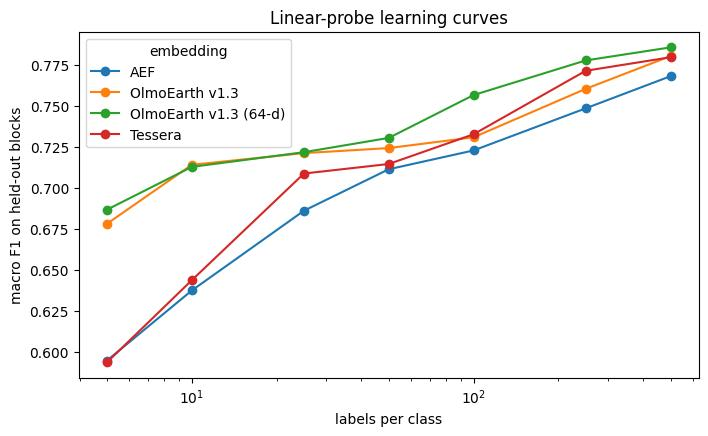

In [21]:
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0).split(y, y, groups))
n_per_class = [5, 10, 25, 50, 100, 250, 500]
curves = []
for feat_name, X in features.items():
    for n in n_per_class:
        for seed in range(3):
            r = np.random.default_rng(seed)
            pick = np.concatenate([r.choice(train_idx[y[train_idx] == k], min(n, (y[train_idx] == k).sum()),
                                            replace=False) for k in range(len(classes))])
            clf = models['linear probe'].fit(X[pick], y[pick])
            curves.append({'embedding': feat_name, 'labels per class': n,
                           'macro_F1': f1_score(y[test_idx], clf.predict(X[test_idx]), average='macro')})

ax = pd.DataFrame(curves).groupby(['labels per class', 'embedding']).macro_F1.mean().unstack().plot(
    marker='o', logx=True, figsize=(8, 4.5))
ax.set_ylabel('macro F1 on held-out blocks')
ax.set_title('Linear-probe learning curves')
plt.show()

Even 5–10 labels per class give a usable first map, and performance keeps improving up to the 500 labels per class we tried, with no plateau yet. The products also differ most when labels are scarce: here OlmoEarth is markedly more label-efficient at the low end, while the curves converge as labels grow. That is the practical appeal of embeddings: a first map from an afternoon of labelling, which gets better as labels are added.

### Fine-tuning a small head on frozen embeddings

"Fine-tuning" in the full sense means updating the foundation model's own weights, which requires the source imagery, the model and usually a GPU. With pre-computed embeddings, the cheap and very effective alternative is to keep the encoder frozen and **train a small neural-network head** on top. This is the same pattern as a linear probe with more capacity, and a two-layer MLP trains in seconds on a CPU.

The training loop below is deliberately plain PyTorch, so it can be adapted to other heads, losses (it is reused for regression in section 5) or a GPU. We use the AEF features and the same spatial train/test split as the learning curve, holding out a further 15% of the training blocks for early stopping.

In [22]:
class Head(torch.nn.Module):
    def __init__(self, d_in, d_out, hidden=256, dropout=0.2):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(d_in, hidden), torch.nn.ReLU(), torch.nn.Dropout(dropout),
            torch.nn.Linear(hidden, hidden), torch.nn.ReLU(), torch.nn.Dropout(dropout),
            torch.nn.Linear(hidden, d_out))

    def forward(self, x):
        return self.net(x)


def train_head(X_tr, y_tr, X_va, y_va, d_out, loss_fn, epochs=200, lr=1e-3, batch_size=256, patience=20):
    """Train a Head with Adam and early stopping on validation loss; returns (model, scaler, history)."""
    scaler = StandardScaler().fit(X_tr)
    to_t = lambda a: torch.as_tensor(scaler.transform(a), dtype=torch.float32)
    X_tr_t, X_va_t = to_t(X_tr), to_t(X_va)
    y_tr_t, y_va_t = torch.as_tensor(y_tr), torch.as_tensor(y_va)
    model = Head(X_tr.shape[1], d_out)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(epochs):
        model.train()
        for batch in torch.randperm(len(X_tr_t)).split(batch_size):
            opt.zero_grad()
            loss_fn(model(X_tr_t[batch]), y_tr_t[batch]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_va_t), y_va_t).item()
        history.append(val)
        if val < best:
            best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        elif (wait := wait + 1) >= patience:
            break
    model.load_state_dict(best_state)
    return model, scaler, history


def predict(model, scaler, X, batch=200_000):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(torch.as_tensor(scaler.transform(X[i:i + batch]), dtype=torch.float32))
                          for i in range(0, len(X), batch)]).numpy()

In [23]:
X = features['AEF']
fit_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=1)
                        .split(train_idx, y[train_idx], groups[train_idx]))
fit_idx, val_idx = train_idx[fit_idx], train_idx[val_idx]

t0 = time.perf_counter()
head, head_scaler, history = train_head(X[fit_idx], y[fit_idx], X[val_idx], y[val_idx], d_out=len(classes),
                                        loss_fn=torch.nn.CrossEntropyLoss())
print(f'trained {len(history)} epochs in {time.perf_counter() - t0:.0f} s on CPU')

linear = models['linear probe'].fit(X[train_idx], y[train_idx])
pred_head = predict(head, head_scaler, X[test_idx]).argmax(axis=1)
pred_lin = linear.predict(X[test_idx])
pd.DataFrame({
    'linear probe': [accuracy_score(y[test_idx], pred_lin), f1_score(y[test_idx], pred_lin, average='macro')],
    'MLP head': [accuracy_score(y[test_idx], pred_head), f1_score(y[test_idx], pred_head, average='macro')],
}, index=['accuracy', 'macro F1']).round(3)

trained 38 epochs in 3 s on CPU


,linear probe,MLP head
accuracy,0.787,0.799
macro F1,0.783,0.796


The MLP head adds about a point over the linear probe. That is typical: good embeddings make most of the signal linearly accessible, and a non-linear head pays off more with more labels or less linear targets (compare the regression in section 5). Per-class errors show where the remaining confusion lies, mostly between the vegetation classes, where WorldCover's own labels are least reliable:

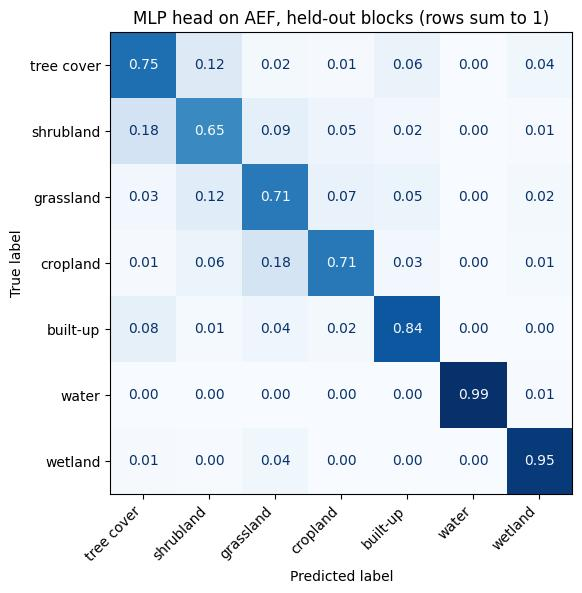

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y[test_idx], pred_head, display_labels=class_names, normalize='true',
                                        values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
ax.set_title('MLP head on AEF, held-out blocks (rows sum to 1)')
plt.xticks(rotation=45, ha='right')
plt.show()

Finally, apply the head to **every pixel** in the AOI, about 1.2 million predictions in a couple of seconds, and compare the map with WorldCover:

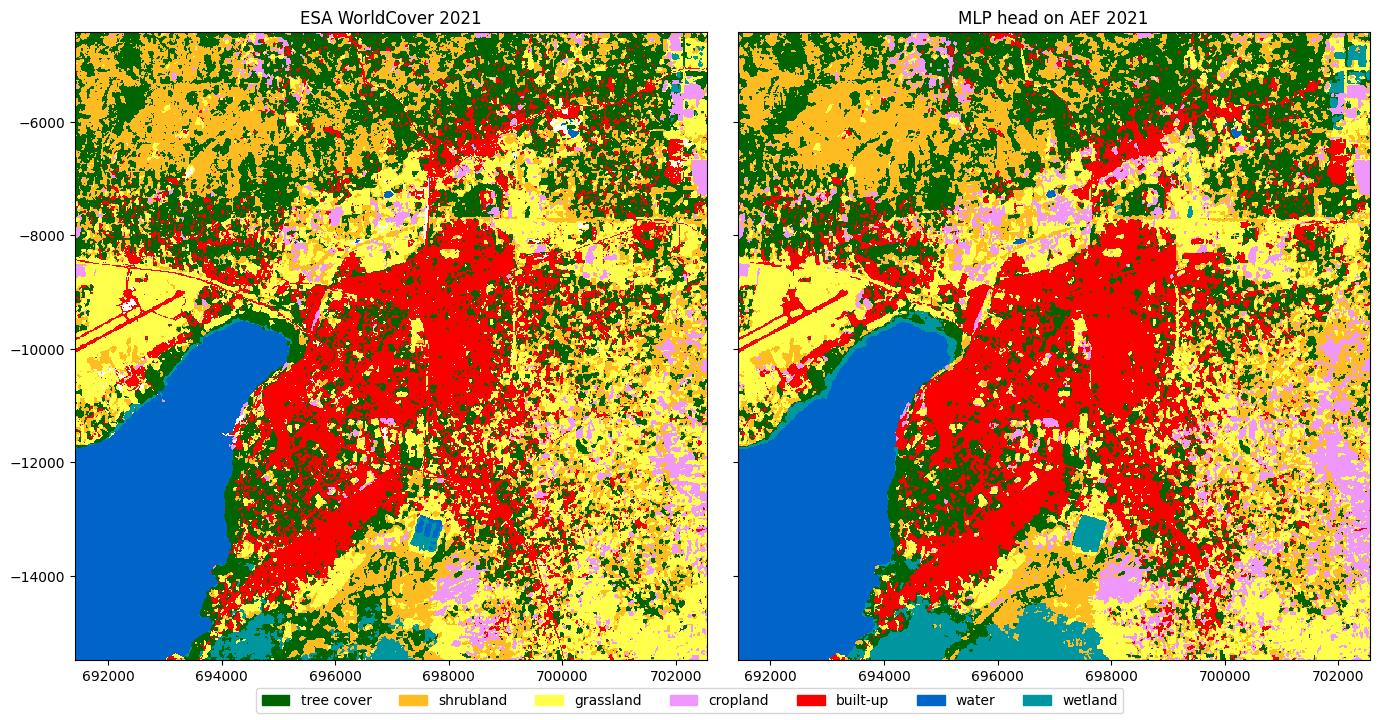

In [25]:
wc_colors = {10: '#006400', 20: '#ffbb22', 30: '#ffff4c', 40: '#f096ff', 50: '#fa0000', 60: '#b4b4b4',
             80: '#0064c8', 90: '#0096a0'}
class_cmap = ListedColormap([wc_colors[c] for c in classes])

aef_all = mats['AEF']
ok = ~np.isnan(aef_all).any(axis=1)
pred_map = np.full(H * W, -1)
pred_map[ok] = predict(head, head_scaler, aef_all[ok]).argmax(axis=1)
label_map = np.where(np.isin(labels, classes), np.searchsorted(classes, labels), -1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, (title, m) in zip(axes, [('ESA WorldCover 2021', label_map), ('MLP head on AEF 2021', pred_map.reshape(H, W))]):
    ax.imshow(np.ma.masked_less(m, 0), cmap=class_cmap, vmin=-0.5, vmax=len(classes) - 0.5,
              interpolation='nearest', extent=extent_of(grid))
    ax.set_title(title)
handles = [plt.Rectangle((0, 0), 1, 1, color=wc_colors[c]) for c in classes]
fig.legend(handles, class_names, loc='lower center', ncol=len(classes))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 5. Regression: canopy height in Kakamega Forest

Embeddings work just as well for continuous targets. [Kakamega Forest](https://en.wikipedia.org/wiki/Kakamega_Forest), 40 km north of Kisumu, is Kenya's last fragment of Guineo-Congolian rainforest, surrounded by dense smallholder farms. That gives a wide range of canopy heights in a small area.

As the target we use **Meta's global canopy height map v2**, published as cloud-native COGs with a GeoParquet tile index on [Source Cooperative](https://source.coop/tge-labs/meta-chm-v2). Like WorldCover, it is itself a model output, so we are really learning to reproduce it. Its source imagery for this tile dates from 2012–2020, so we pair it with AEF 2020.

The CHM's native resolution is ~1.2 m. We read its 8× overview (~9.5 m) and resample to the AEF grid with **averaging**. Averaging is right for a continuous target, unlike for embeddings or class labels.

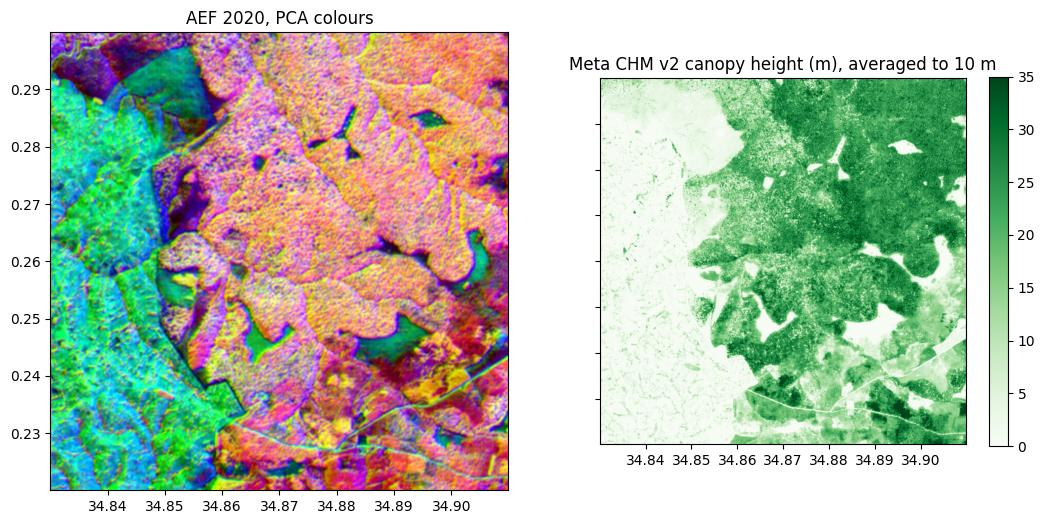

In [26]:
KAKAMEGA = (34.83, 0.22, 34.91, 0.30)
kak_raw = cached('aef_kakamega_2020', lambda: read_aef_mosaic(KAKAMEGA, 2020), crs='EPSG:4326')
kak = dequantize_signed_square(kak_raw)


def read_chm(bbox, like):
    con = duckdb.connect()
    con.sql("LOAD spatial; LOAD httpfs; SET s3_region='us-west-2';")
    tiles = con.sql(f'''
        SELECT cog_url FROM '{SOURCE_COOP_S3}/tge-labs/meta-chm-v2/tiles.parquet'
        WHERE bbox.xmin < {bbox[2]} AND bbox.xmax > {bbox[0]} AND bbox.ymin < {bbox[3]} AND bbox.ymax > {bbox[1]}
    ''').fetchall()
    assert len(tiles) == 1, 'this helper assumes the AOI sits inside one CHM tile'
    chm = rioxarray.open_rasterio(tiles[0][0], overview_level=2).squeeze(drop=True)
    return (chm.rio.clip_box(*bbox, crs='EPSG:4326').astype(np.float32).rio.write_nodata(np.nan)
            .rio.reproject_match(like, resampling=Resampling.average))


chm = cached('chm_kakamega', lambda: read_chm(KAKAMEGA, kak), crs='EPSG:4326')

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].imshow(pca_rgb(to_matrix(kak)).reshape(*kak.shape[1:], 3), extent=extent_of(kak))
axes[0].set_title('AEF 2020, PCA colours')
im = axes[1].imshow(chm, extent=extent_of(chm), cmap='Greens', vmin=0, vmax=35)
axes[1].set_title('Meta CHM v2 canopy height (m), averaged to 10 m')
plt.colorbar(im, ax=axes[1], shrink=0.8)
plt.show()

Same recipe as before: spatial blocks, a fixed held-out test set, a linear model (ridge regression) and the MLP head with a mean-squared-error loss.

In [27]:
Xk, yk = to_matrix(kak), chm.values.ravel()
ok = ~np.isnan(Xk).any(axis=1) & np.isfinite(yk)
hk, wk = chm.shape
r, c = np.unravel_index(np.arange(hk * wk), (hk, wk))
groups_k = (r // 100) * 1000 + c // 100

pool = rng.choice(np.flatnonzero(ok), 40_000, replace=False)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0).split(pool, groups=groups_k[pool]))
tr, te = pool[tr], pool[te]
fit, va = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=1).split(tr, groups=groups_k[tr]))
fit, va = tr[fit], tr[va]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xk[tr], yk[tr])
reg_head, reg_scaler, _ = train_head(Xk[fit], yk[fit, None].astype(np.float32), Xk[va], yk[va, None].astype(np.float32),
                                     d_out=1, loss_fn=torch.nn.MSELoss())
preds = {'ridge': ridge.predict(Xk[te]), 'MLP head': predict(reg_head, reg_scaler, Xk[te])[:, 0]}
pd.DataFrame({name: {'R²': r2_score(yk[te], p), 'MAE (m)': mean_absolute_error(yk[te], p)}
              for name, p in preds.items()}).round(2)

,ridge,MLP head
R²,0.72,0.8
MAE (m),3.76,3.1


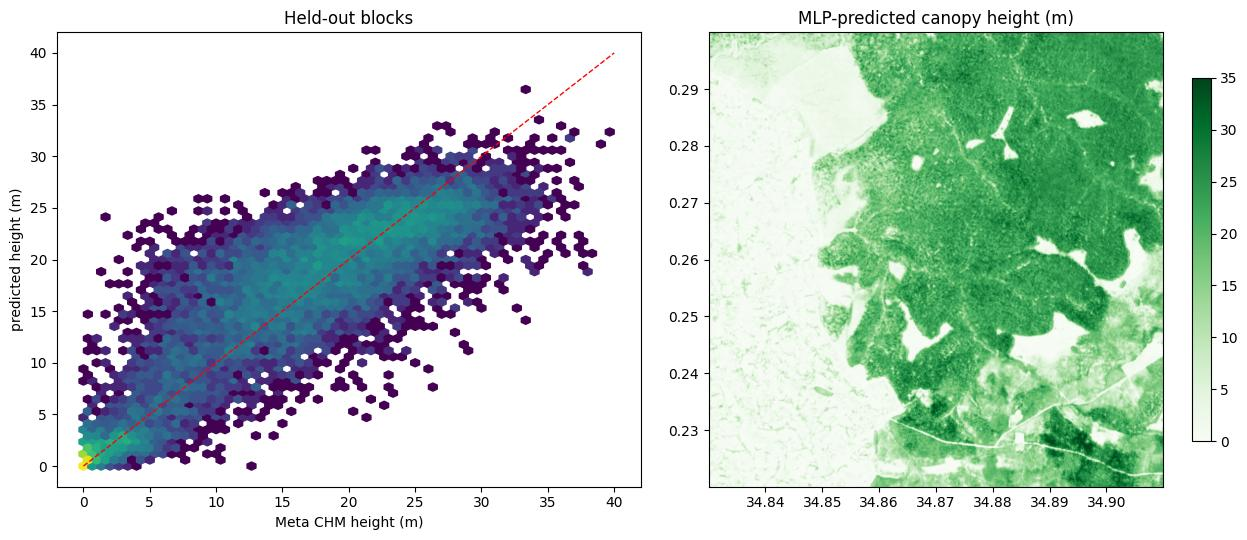

In [28]:
height_map = np.full(hk * wk, np.nan)
height_map[ok] = predict(reg_head, reg_scaler, Xk[ok])[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].hexbin(yk[te], preds['MLP head'], gridsize=60, bins='log', cmap='viridis', extent=(0, 40, 0, 40))
axes[0].plot([0, 40], [0, 40], 'r--', lw=1)
axes[0].set_xlabel('Meta CHM height (m)')
axes[0].set_ylabel('predicted height (m)')
axes[0].set_title('Held-out blocks')
im = axes[1].imshow(height_map.reshape(hk, wk), extent=extent_of(chm), cmap='Greens', vmin=0, vmax=35)
axes[1].set_title('MLP-predicted canopy height (m)')
plt.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()

From 64 numbers per pixel, the model recovers the forest/farmland boundary and much of the within-forest variation. Here the MLP head clearly beats the linear model (R² 0.80 vs 0.72), because canopy height is a less linear function of the embedding than land-cover class. The scatter plot also shows the predictions compressing the extremes, under-predicting the tallest trees: a 10 m annual embedding cannot see individual crowns.

## 6. Comparing models at global scale: two training objectives

The Major TOM *Core-S2L2A-249k* family embeds the **same 248,719 Sentinel-2 chips** with several models, a ready-made, apples-to-apples benchmark. Here we compare two image encoders trained in very different ways:

- **OlmoEarth-Base**, an Earth-observation foundation model trained by masked modelling on Sentinel-2 and derived maps. This is the earlier, chip-level OlmoEarth model, not the v1.3 pixel product from section 4.
- **SatCLIP's image encoder**, a ResNet-50 trained *contrastively against location*: it learns image features that predict where on Earth a chip was taken. (SatCLIP also has a separate *location* encoder that embeds bare coordinates; that is not what this file contains.)

Both files are single-row-group Parquet, so we download them once (~1.1 GB) with `huggingface_hub`. To keep memory low, DuckDB then streams through the local files and keeps a deterministic 1-in-5 sample (~50k chips). Hashing the chip id and acquisition selects the same chips from both files, and sorting on the same keys lines them up row for row.

In [29]:
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import disable_progress_bars

disable_progress_bars()

files = {
    'OlmoEarth-Base': ('Major-TOM/Core-S2L2A-249k-OlmoEarth-Base', 'OlmoEarth_Base_crop_384x384.parquet'),
    'SatCLIP': ('Major-TOM/Core-S2L2A-249k-SatCLIP', 'SatCLIP_crop_384x384.parquet'),
}
paths = {name: hf_hub_download(repo, fname, repo_type='dataset', local_dir=CACHE / 'major_tom')
         for name, (repo, fname) in files.items()}

mt = {}
for name, path in paths.items():
    mt[name] = duckdb.sql(f'''
        SELECT grid_cell, product_id, centre_lat, centre_lon, embedding
        FROM '{path}' WHERE hash(grid_cell || product_id) % 5 = 0
        ORDER BY grid_cell, product_id
    ''').df()
assert (mt['OlmoEarth-Base'].grid_cell.values == mt['SatCLIP'].grid_cell.values).all()
lat, lon = mt['SatCLIP'].centre_lat.to_numpy(), mt['SatCLIP'].centre_lon.to_numpy()
E = {name: l2_normalize(np.stack(df.embedding.to_numpy()).astype(np.float32)) for name, df in mt.items()}
print({name: e.shape for name, e in E.items()})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'OlmoEarth-Base': (49644, 768), 'SatCLIP': (49644, 256)}


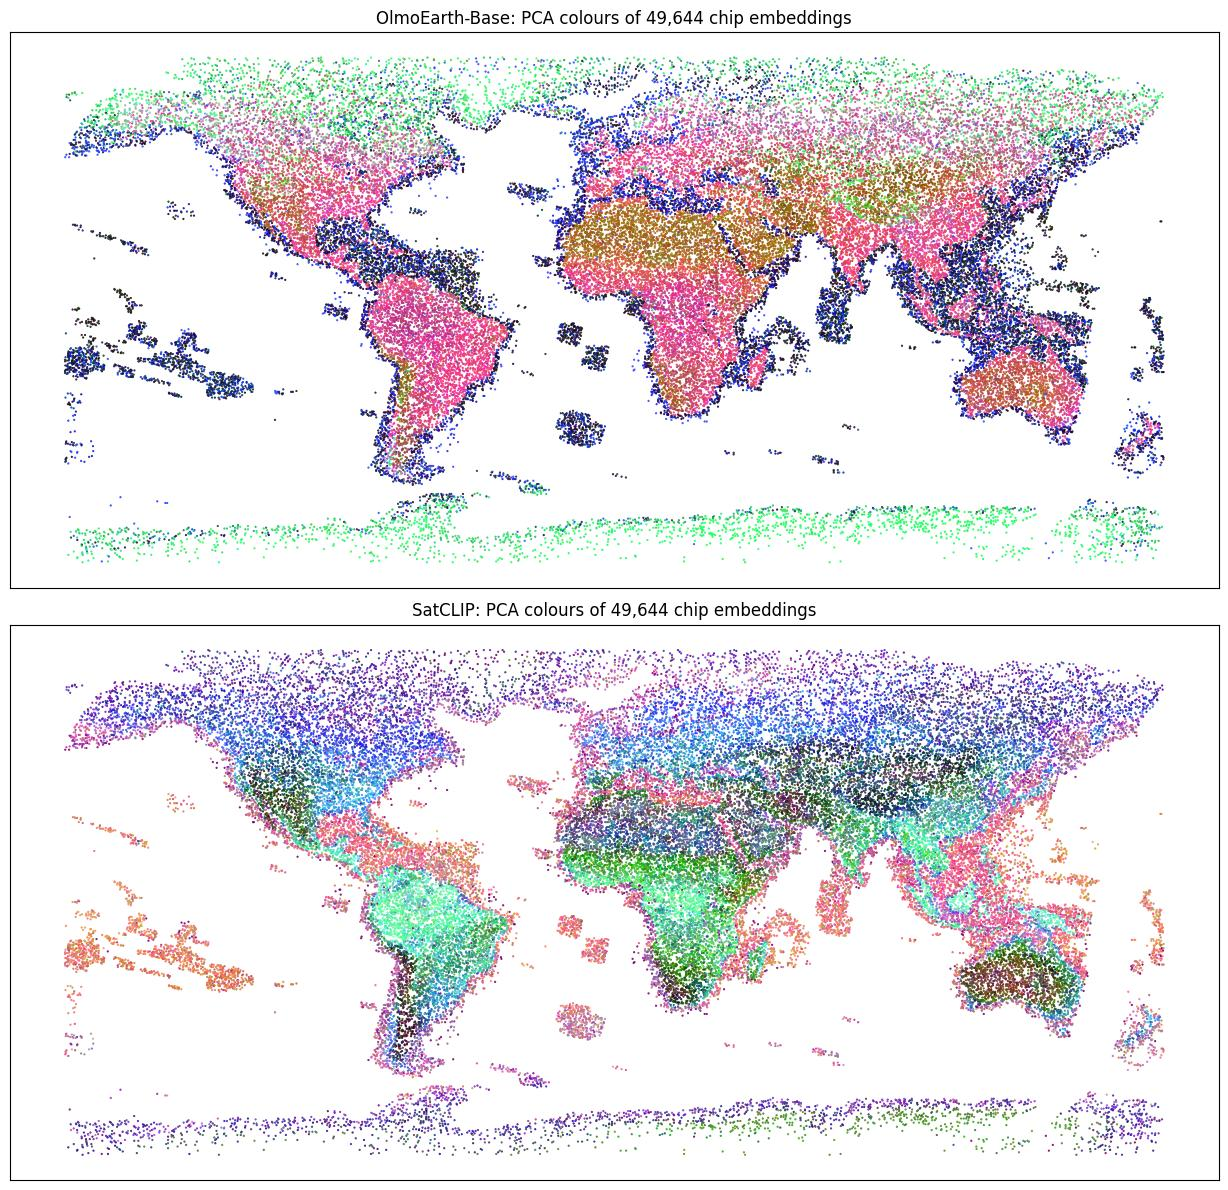

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(13, 12))
for ax, (name, e) in zip(axes, E.items()):
    ax.scatter(lon, lat, s=0.3, c=pca_rgb(e), rasterized=True)
    ax.set_title(f'{name}: PCA colours of {len(e):,} chip embeddings')
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

The maps already hint at the difference. OlmoEarth's colours track **surface type** and repeat across continents: deserts, ice and coasts look alike wherever they are. SatCLIP's colours follow broader **geographic and climatic gradients**, such as the boreal belt, the tropics and the Australian interior, as its location-based training objective would suggest.

We can quantify this by asking where each model's nearest neighbours are. For 2,000 random chips, we find the 10 most similar chips in each embedding space with FAISS and measure the great-circle distance to them:

In [31]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))


queries = rng.choice(len(lat), 2000, replace=False)
neighbours, summary = {}, []
for name, e in E.items():
    index = faiss.IndexFlatIP(e.shape[1])
    index.add(e)
    _, nn = index.search(e[queries], 11)
    neighbours[name] = nn[:, 1:]  # drop the query itself
    dist = haversine_km(lat[queries, None], lon[queries, None], lat[nn[:, 1:]], lon[nn[:, 1:]])
    summary.append({'model': name, 'median km to 10 nearest neighbours': np.median(dist),
                 'share of neighbours > 1,000 km away': (dist > 1000).mean()})

overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(neighbours['OlmoEarth-Base'], neighbours['SatCLIP'])])
print(f'average overlap between the two models\' neighbour lists: {overlap:.1%}')
pd.DataFrame(summary).set_index('model').round(2)

average overlap between the two models' neighbour lists: 18.6%


,median km to 10 nearest neighbours,"share of neighbours > 1,000 km away"
model,,
OlmoEarth-Base,3884.679932,0.78
SatCLIP,3105.479980,0.72


For both models most neighbours are more than 1,000 km away: similar-looking places recur all over the planet. SatCLIP's neighbours are measurably closer, though, and the two models agree on fewer than one in five neighbours. **The training objective shapes what "similar" means.** Location-aware features are a good prior for tasks driven by geography and climate, such as species distributions; appearance-focused features suit mapping what is on the ground. Neither is "better" in general, and concatenating embeddings from different models is a cheap way to combine their strengths. The linear-probe recipe from section 4 tells you whether it helps for your task.

### Interactive exploration

For exploring hundreds of thousands of points, [Lonboard](https://developmentseed.org/lonboard/) renders them on the GPU in the browser via deck.gl. The map below is interactive when you run the notebook in Jupyter; it does not appear on the static website.

In [32]:
import geopandas as gpd
from lonboard import Map, ScatterplotLayer

points = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon, lat), crs='EPSG:4326')
layer = ScatterplotLayer.from_geopandas(points, get_fill_color=(pca_rgb(E['OlmoEarth-Base']) * 255).astype(np.uint8),
                                        get_radius=3000, radius_min_pixels=1)
Map(layer)

## Where to go next

- **Better labels beat bigger models.** Every result here is bounded by the quality of WorldCover and the Meta CHM. Swap in field data or your own labels, for example by clicking points in QGIS or Lonboard and sampling embeddings at them, as the classification section does.
- **Combine products and years.** Concatenating AEF + Tessera + OlmoEarth, or stacking several years, is a cheap way to add information; the linear-probe table tells you whether it helped.
- **Scale up without changing the code.** The block-wise `partial_fit` pattern from section 2 and the `predict` helper from section 4 work on AOIs of any size when you stream windows from the Zarr stores instead of loading them.
- **Full fine-tuning** of an encoder (OlmoEarth, Clay, Prithvi, Galileo) needs imagery and usually a GPU. [TorchGeo](https://torchgeo.readthedocs.io) and the model providers' repositories have recipes, and the embedding-based baselines here are what such a model has to beat.
- **Vector search at scale.** The appendix below compares exact search, IVF, IVF-PQ and HNSW, and explains when the similarity metric matters.

## Appendix: vector search in practice

Section 1 searched 1.7 million vectors exhaustively, and that took milliseconds. This appendix covers the two questions that come up as soon as datasets grow, or results look odd:

1. **Which index?** When exact search stops being fast enough, what do approximate indexes trade away?
2. **Which similarity metric?** Cosine, dot product or Euclidean distance, and when does the choice matter?

Everything runs on data already loaded: the Almería AEF vectors from section 1 and the Kisumu OlmoEarth vectors from section 4.

### A.1 Index families

| Index | How it works | Memory per vector (64-d) | Trade-off |
|---|---|---|---|
| **Flat** | Compares the query with every vector | 256 bytes (float32) | Exact. Query time grows linearly with the number of vectors |
| **IVF** | k-means splits the vectors into `nlist` cells; a query searches only the `nprobe` nearest cells | ~256 bytes | Needs training. `nprobe` trades recall for speed |
| **IVF-PQ** | IVF plus *product quantization*: each vector is cut into `m` sub-vectors, and each is replaced by a 1-byte code for its nearest centroid | `m` bytes (16 here) | 16× smaller, but distances are approximate. Often paired with exact re-ranking of the candidates |
| **HNSW** | A layered proximity graph explored greedily from coarse to fine | ~256 bytes + graph links | Highest recall at low latency. Slowest to build, largest in memory |

Product quantization is the index-side cousin of the int8 storage quantization discussed in section 1: both trade precision for size. PQ just goes much further, from 64 floats down to 16 bytes.

We index 500,000 Almería pixels and query with 1,000 *other* pixels. Two quality measures: **recall@10**, the share of the true 10 nearest neighbours that the index returns, and **similarity lost**, how much less similar the returned neighbours are than the true ones. The second matters because these pixels contain many near-duplicates. Several "wrong" neighbours can be practically as good as the right ones.

In [33]:
d, k = X_alm.shape[1], 10
pool = rng.permutation(np.flatnonzero(alm_valid))
base = np.ascontiguousarray(X_alm[pool[:500_000]])
queries = np.ascontiguousarray(X_alm[pool[500_000:501_000]])  # held-out pixels, not in the index

exact = faiss.IndexFlatIP(d)  # inner product == cosine similarity for unit vectors
exact.add(base)
t0 = time.perf_counter()
true_sim, truth = exact.search(queries, k)
exact_ms = 1000 * (time.perf_counter() - t0) / len(queries)


def evaluate(name, index, configure=lambda: None, train_size=100_000):
    """Build `index` on `base`, query it, and compare against exact search."""
    t0 = time.perf_counter()
    if not index.is_trained:
        index.train(base[:train_size])
    index.add(base)
    build_s = time.perf_counter() - t0
    configure()
    t0 = time.perf_counter()
    _, found = index.search(queries, k)
    query_ms = 1000 * (time.perf_counter() - t0) / len(queries)
    found_sim = np.einsum('qd,qkd->qk', queries, base[found])  # exact similarity of what the index returned
    return {'index': name, 'build (s)': build_s, 'query (ms)': query_ms,
            'memory (MB)': faiss.serialize_index(index).nbytes / 1e6,
            'recall@10': np.mean([len(set(f) & set(t)) / k for f, t in zip(found, truth)]),
            'similarity lost': (true_sim - found_sim).mean()}


def ivf_flat():
    return faiss.IndexIVFFlat(faiss.IndexFlatIP(d), d, 1024, faiss.METRIC_INNER_PRODUCT)


def ivf_pq():
    return faiss.IndexIVFPQ(faiss.IndexFlatIP(d), d, 1024, 16, 8, faiss.METRIC_INNER_PRODUCT)  # 16 x 1-byte codes


ivf_a, ivf_b, pq = ivf_flat(), ivf_flat(), ivf_pq()
pq_base = ivf_pq()
pq_rerank = faiss.IndexRefineFlat(pq_base)  # re-scores PQ candidates with the exact vectors
hnsw = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT)


def rerank_settings():
    pq_base.nprobe = 32
    pq_rerank.k_factor = 10  # fetch 10 x k candidates, keep the best k by exact similarity


benchmark = pd.DataFrame([
    {'index': 'Flat (exact)', 'build (s)': 0.0, 'query (ms)': exact_ms,
     'memory (MB)': faiss.serialize_index(exact).nbytes / 1e6, 'recall@10': 1.0, 'similarity lost': 0.0},
    evaluate('IVF, nprobe=4', ivf_a, lambda: setattr(ivf_a, 'nprobe', 4)),
    evaluate('IVF, nprobe=32', ivf_b, lambda: setattr(ivf_b, 'nprobe', 32)),
    evaluate('IVF-PQ, 16 bytes', pq, lambda: setattr(pq, 'nprobe', 32)),
    evaluate('IVF-PQ, 16 bytes + exact re-rank', pq_rerank, rerank_settings),
    evaluate('HNSW, M=32', hnsw, lambda: setattr(hnsw.hnsw, 'efSearch', 64)),
]).set_index('index')
benchmark.round({'build (s)': 1, 'query (ms)': 3, 'memory (MB)': 0, 'recall@10': 3, 'similarity lost': 4})

,build (s),query (ms),memory (MB),recall@10,similarity lost
index,,,,,
Flat (exact),0.0,4.831,128.0,1.000,0.0000
"IVF, nprobe=4",2.9,0.031,132.0,0.741,0.0008
"IVF, nprobe=32",2.9,0.226,132.0,0.936,0.0000
"IVF-PQ, 16 bytes",14.6,0.139,12.0,0.297,0.0063
"IVF-PQ, 16 bytes + exact re-rank",14.7,0.170,140.0,0.734,0.0005
"HNSW, M=32",40.5,0.155,264.0,0.996,0.0000


How to read this (FAISS is limited to one thread in this notebook, so absolute timings are pessimistic):

- **Flat** is already only a few milliseconds per query at 500k vectors. Below a few million vectors, exact search is usually the right answer: no training, no tuning, no surprises.
- **IVF** is the workhorse. It is an order of magnitude faster, and `nprobe` is a single dial between speed and recall.
- **IVF-PQ** is tiny but, on its own, finds only a minority of the true top 10. Look at the *similarity lost* column, though: its neighbours are nearly as similar as the true ones, because in a landscape full of near-identical greenhouse pixels many candidates are almost interchangeable. **Exact re-ranking** of a larger PQ candidate list recovers most of the recall. It needs the full vectors at hand, but they can stay on disk and be fetched only for the candidates.
- **HNSW** gets near-perfect recall at sub-millisecond latency, at the cost of the slowest build and the largest memory footprint.

Memory is what decides the choice at scale. Extrapolating the per-vector cost (one year of AEF over Switzerland alone is ~400 million pixels):

In [34]:
per_vector = benchmark['memory (MB)'] * 1e6 / len(base)
pd.DataFrame({f'{n:,} vectors': per_vector * n / 1e9 for n in [10**6, 10**8, 10**9]}).round(1).rename(
    columns=lambda c: f'{c} (GB)')

,"1,000,000 vectors (GB)","100,000,000 vectors (GB)","1,000,000,000 vectors (GB)"
index,,,
Flat (exact),0.3,25.6,256.0
"IVF, nprobe=4",0.3,26.5,264.5
"IVF, nprobe=32",0.3,26.5,264.5
"IVF-PQ, 16 bytes",0.0,2.5,24.7
"IVF-PQ, 16 bytes + exact re-rank",0.3,28.1,280.7
"HNSW, M=32",0.5,52.8,528.1


Indexes can be saved and memory-mapped back, so a large index does not need to be rebuilt each session or fit in RAM:

In [35]:
index_path = CACHE / 'almeria_ivfpq.faiss'
faiss.write_index(pq, str(index_path))
reloaded = faiss.read_index(str(index_path), faiss.IO_FLAG_MMAP)
reloaded.nprobe = 32
print(f'{index_path.stat().st_size / 1e6:.1f} MB on disk; reloaded index returns the same neighbours: '
      f'{(reloaded.search(queries[:5], k)[1] == pq.search(queries[:5], k)[1]).all()}')

12.3 MB on disk; reloaded index returns the same neighbours: True


### A.2 Cosine, dot product or Euclidean?

For two vectors **a** and **b**: the dot product is **a · b**, cosine similarity is **a · b / (‖a‖ ‖b‖)**, and Euclidean distance is ‖**a** − **b**‖. When every vector has unit length (‖a‖ = ‖b‖ = 1), the three are tied together exactly:

‖**a** − **b**‖² = ‖a‖² + ‖b‖² − 2 **a · b** = 2 − 2 cos(**a**, **b**)

So for unit vectors they all produce **the same ranking**, and you can pick whichever your tools support. AEF is *nearly* unit length: int8 rounding leaves lengths within about ±0.5% of 1. Here is how much that "nearly" matters:

In [36]:
def overlap(a, b):
    """Average share of neighbours two top-k lists have in common."""
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(a, b)])


def top_k(index, X, Q):
    index.add(np.ascontiguousarray(X))
    return index.search(np.ascontiguousarray(Q), k)[1]


lengths = np.linalg.norm(base, axis=1)
by_l2 = top_k(faiss.IndexFlatL2(d), base, queries)
l2_sim = np.einsum('qd,qkd->qk', queries, base[by_l2])
print(f'AEF vector lengths: {np.percentile(lengths, 1):.4f}-{np.percentile(lengths, 99):.4f} (1st-99th percentile)')
print(f'as stored:            Euclidean vs cosine top-{k} overlap {overlap(by_l2, truth):.1%}, '
      f'similarity lost {(true_sim - l2_sim).mean():.4f}')

unit_base, unit_queries = l2_normalize(base), l2_normalize(queries)
print(f'after normalization:  Euclidean vs cosine top-{k} overlap '
      f'{overlap(top_k(faiss.IndexFlatL2(d), unit_base, unit_queries), top_k(faiss.IndexFlatIP(d), unit_base, unit_queries)):.2%}')

AEF vector lengths: 0.9954-1.0048 (1st-99th percentile)
as stored:            Euclidean vs cosine top-10 overlap 62.3%, similarity lost 0.0018


after normalization:  Euclidean vs cosine top-10 overlap 99.98%


Among near-duplicate pixels, even ±0.5% length differences reshuffle about a third of the top 10, although the substitutes are practically as similar. After exact normalization, the identity holds and the two metrics agree. So for AEF, cosine and Euclidean are interchangeable in practice. If you need rankings that agree exactly across tools or metrics, normalize first.

Most other products are **not** unit length: Tessera, OlmoEarth, Clay, Earth Index and the Major TOM sets. Then the three metrics disagree, and the choice is a modelling decision. OlmoEarth's documentation notes that its vector length carries signal. Let's see how much the metric changes the neighbours of the Kisumu OlmoEarth vectors from section 4:

In [37]:
olmo = mats['OlmoEarth v1.3']
olmo = olmo[~np.isnan(olmo).any(axis=1)]
pick = rng.choice(len(olmo), 300_500, replace=False)
o_base, o_queries = np.ascontiguousarray(olmo[pick[:300_000]]), np.ascontiguousarray(olmo[pick[300_000:]])
o_norms = np.linalg.norm(o_base, axis=1)
print(f'vector lengths: 1st percentile {np.percentile(o_norms, 1):.2f}, median {np.median(o_norms):.2f}, '
      f'99th percentile {np.percentile(o_norms, 99):.2f}')


def neighbours(index, X, Q):
    index.add(np.ascontiguousarray(X))
    return index.search(np.ascontiguousarray(Q), k)[1]


dim = o_base.shape[1]
by_metric = {
    'cosine': neighbours(faiss.IndexFlatIP(dim), l2_normalize(o_base), l2_normalize(o_queries)),
    'Euclidean': neighbours(faiss.IndexFlatL2(dim), o_base, o_queries),
    'dot product': neighbours(faiss.IndexFlatIP(dim), o_base, o_queries),
}
longest = o_norms >= np.percentile(o_norms, 90)
pd.DataFrame({
    'overlap with cosine top-10': {m: np.mean([len(set(a) & set(b)) / k for a, b in zip(nn, by_metric['cosine'])])
                                   for m, nn in by_metric.items()},
    'share of neighbours from the longest 10% of vectors': {m: longest[nn].mean() for m, nn in by_metric.items()},
}).round(3)

vector lengths: 1st percentile 2.52, median 3.02, 99th percentile 3.46


,overlap with cosine top-10,share of neighbours from the longest 10% of vectors
cosine,1.000,0.108
Euclidean,0.928,0.091
dot product,0.046,0.841


- **Cosine** ignores length and compares direction only. It is the safe default for similarity search.
- **Euclidean** also penalizes differences in length. Use it when length is meaningful for your task and comparable across the dataset (within one product and one year, for example).
- **Raw dot product** on unnormalized vectors rewards *long* vectors regardless of the query: the longest 10% of vectors take a disproportionate share of everyone's neighbour lists. This "hub" effect is almost never what you want.

In practice: **L2-normalize once** (`faiss.normalize_L2` does it in place) and use an inner-product index. You get cosine similarity with the fastest index type. For AEF, normalizing is optional but cheap.

### A.3 Vector search inside a database

If your embeddings already live in tables, as the scene products in the first notebook do, you may not need a separate vector library at all. DuckDB's [`vss` extension](https://duckdb.org/docs/extensions/vss) adds HNSW indexes to ordinary SQL tables:

In [38]:
con = duckdb.connect()
con.sql('INSTALL vss; LOAD vss;')
pixels_df = pd.DataFrame({'id': np.arange(100_000), 'embedding': list(base[:100_000])})
con.sql('CREATE TABLE pixels AS SELECT id, embedding::FLOAT[64] AS embedding FROM pixels_df')
con.sql("CREATE INDEX pixels_hnsw ON pixels USING HNSW (embedding) WITH (metric = 'cosine')")

nearest = '''
    SELECT id, array_cosine_distance(embedding, ?::FLOAT[64]) AS cosine_distance
    FROM pixels ORDER BY cosine_distance LIMIT 5
'''
plan = con.execute('EXPLAIN ' + nearest, [queries[0].tolist()]).fetchall()[0][1]
print('query plan uses the HNSW index:', 'HNSW' in plan)
con.execute(nearest, [queries[0].tolist()]).df()

query plan uses the HNSW index: True


,id,cosine_distance
0,5183,0.031213
1,84598,0.035616
2,56982,0.039738
3,89119,0.042151
4,62634,0.043135


At the time of writing, persisting an HNSW index inside a DuckDB database *file* is behind an experimental setting (`hnsw_enable_experimental_persistence`), so check the extension's documentation before relying on it. Embedded vector databases such as [LanceDB](https://lancedb.com) offer the same no-server workflow with on-disk IVF-PQ and HNSW indexes. For large, multi-user deployments, server-based options like pgvector are the usual next step.